# Evaluation notebook v2 (Colab CPU)

Scores every run trained by **Training notebook v2** from its saved predictions. Nothing is retrained, so a **CPU runtime** is enough (~5 min for the whole notebook).

**How models are scored**
- **Weather:** the highest of the 4 weather probabilities is the prediction (no threshold).
- **Land labels:** each label gets its own threshold, tuned on the **validation set** to maximize that label's F2. The same thresholds are then applied unchanged to the **test set**.
- **Main metric: deforestation F2.** This is the average F2 over `selective_logging`, `slash_burn`, `artisinal_mine` and `conventional_mine`. Macro F2 (all 17 labels) checks that the other labels don't get worse.
- **Validation vs. test:** compare models on validation. Test scores are for reporting. Tuned thresholds make validation scores slightly optimistic, but equally so for every run.
- **Is a difference real?** A paired bootstrap resamples the chips 1,000 times and scores both runs on each resample. If the 95% interval of the difference excludes 0, the difference is significant. Seed repeats (seeds 42, 1, 2) show how much a score moves from training randomness alone.

**Sections**
1. Settings and loading the runs
2. Metric functions
3. Results table: every run
4. Seed variability
5. Head-to-head comparisons, grouped by question
6. Per-label results and training curves
7. Free extras: ensemble and cloudy rule
8. Figures for the presentation

Outputs (CSV tables and PNG figures) are saved to `ladder_runs_v2/eval/`.

## 1. Settings and loading the runs

In [1]:
import os, re, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import fbeta_score, average_precision_score, precision_recall_curve

DRIVE_DIR = "/content/drive/MyDrive/amazon_caches"
RUNS      = f"{DRIVE_DIR}/ladder_runs_v2"            # written by Training notebook v2
CACHE     = f"{DRIVE_DIR}/amazon_tif_128/cache"      # only labels.json is read from here
OUT       = f"{RUNS}/eval"                            # tables and figures go here
N_BOOT    = 1000                                      # bootstrap resamples

REFERENCE = "r18_imnet_rgb"          # the starting model; most comparisons are against it
FINAL     = "r18_imnet_rgb_prog3"    # the model you present as final (change if you choose another)

try:                                                  # mount Drive when running on Colab
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
os.makedirs(OUT, exist_ok=True)
mpl.rcParams.update({"font.size": 12, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
try:
    display
except NameError:                                     # outside Jupyter, print tables instead
    display = lambda df: print(df.to_string() if hasattr(df, "to_string") else df)

labels  = json.load(open(f"{CACHE}/labels.json"))
WEATHER = ["clear", "partly_cloudy", "haze", "cloudy"]
DEFOR   = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]
WI = [labels.index(l) for l in WEATHER]                       # weather columns
LI = [j for j in range(len(labels)) if j not in WI]           # the 13 land columns
DI = [labels.index(l) for l in DEFOR]                         # the 4 deforestation columns

# The 32 runs of Training notebook v2, in training order (used to order tables and spot missing runs)
PLANNED = [
    "scratch_none_rgb", "scratch_none_rgbnv", "scratch_none_rgb_e28", "scratch_none_rgbnv_e28",
    "r18_none_rgb", "r18_none_rgb_s1", "r18_none_rgb_s2", "r18_none_rgbn", "r18_none_rgb_e28", "r18_none_rgbn_e28",
    "r18_imnet_rgb", "r18_imnet_rgb_s1", "r18_imnet_rgb_s2", "r18_imnet_rgbn", "r18_imnet_rgb_lr0.0003",
    "r18_imnet_rgb_nobal", "r18_imnet_rgb_avgmax",
    "r18_s2_rgb", "r18_s2_rgbn", "r18_s2_rgb_s2rgb", "r18_s2_rgb_s2rgb_s1", "r18_s2_rgb_s2rgb_s2", "r18_s2_rgb_s2rgb_s2norm",
    "r18_imnet_rgb_256", "r18_imnet_rgb_256_s1", "r18_imnet_rgb_256_s2", "effb0_imnet_rgb", "effb0_imnet_rgb_256",
    "r18_imnet_rgb_prog3", "r18_imnet_rgb_prog3_s1", "r18_imnet_rgb_prog3_s2", "r18_s2_rgb_prog3_s2rgb",
]

# Load every run's saved predictions and settings
RUN = {}
for f in sorted(glob.glob(f"{RUNS}/*_probs.npz")):
    name = os.path.basename(f)[:-len("_probs.npz")]
    d = np.load(f)
    sf, hf = f"{RUNS}/{name}_settings.json", f"{RUNS}/{name}_history.json"
    RUN[name] = dict(meta=json.load(open(sf)) if os.path.exists(sf) else {},
                     hist=json.load(open(hf)) if os.path.exists(hf) else [],
                     vp=d["val_probs"], vy=d["val_y"], tp=d["test_probs"], ty=d["test_y"],
                     vidx=d["val_idx"], tidx=d["test_idx"])
ORDER = [n for n in PLANNED if n in RUN] + sorted(n for n in RUN if n not in PLANNED)

# Every run must be scored on exactly the same validation and test chips
first = RUN[ORDER[0]]
assert all((RUN[n]["vidx"] == first["vidx"]).all() and (RUN[n]["tidx"] == first["tidx"]).all() for n in RUN), \
    "runs use different validation/test chips"
print(f"{len(RUN)} runs loaded | validation chips: {len(first['vy'])} | test chips: {len(first['ty'])}")
missing = [n for n in PLANNED if n not in RUN]
print("not trained yet:", missing if missing else "none")

Mounted at /content/drive
32 runs loaded | validation chips: 6072 | test chips: 6072
not trained yet: none


## 2. Metric functions
- `tune` picks each land label's threshold on validation.
- `predict` turns probabilities into yes/no labels.
- `metrics` computes the scores.
- `evaluate(name)` does all three for one run, for validation and test, and remembers the result.
- `bootstrap(a, b)` gives the difference b − a with a 95% interval. It reuses one set of resamples for every comparison, so all comparisons are scored on the same 1,000 resamples.

In [2]:
GRID = np.arange(0.02, 0.81, 0.01)              # candidate thresholds

def tune(y, p):
    """Threshold per land label that maximizes F2 on validation (weather columns stay NaN)."""
    thr = np.full(p.shape[1], np.nan)
    for j in LI:
        pred = p[:, j:j + 1] >= GRID[None, :]
        pos = y[:, j:j + 1] == 1
        tp = (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos).sum(0)
        thr[j] = GRID[(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)).argmax()]
    return thr

def predict(p, thr):
    """Exactly one weather label (the most likely one) + every land label above its threshold."""
    pred = np.zeros(p.shape, dtype=bool)
    pred[np.arange(len(p)), np.array(WI)[p[:, WI].argmax(1)]] = True
    pred[:, LI] = p[:, LI] >= thr[LI]
    return pred

def counts(y, pred):
    y = y.astype(bool)
    return (pred & y).sum(0), (pred & ~y).sum(0), (~pred & y).sum(0)   # TP, FP, FN per label

def f2_from(tp, fp, fn):
    return 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)          # F2 = 5TP / (5TP + 4FN + FP)

def metrics(y, p, pred):
    tp, fp, fn = counts(y, pred)
    f2 = f2_from(tp, fp, fn)
    prec, rec = tp / np.maximum(tp + fp, 1), tp / np.maximum(tp + fn, 1)
    return {"defor_F2": f2[DI].mean(),                     # main metric
            "land_macro_F2": f2[LI].mean(),                # 13 land labels
            "macro_F2": f2.mean(),                         # all 17 labels, each counts equally
            "samples_F2": fbeta_score(y, pred, beta=2, average="samples", zero_division=0),  # Kaggle's metric
            "defor_precision": prec[DI].mean(), "defor_recall": rec[DI].mean(),
            "defor_PR_AUC": np.mean([average_precision_score(y[:, j], p[:, j]) for j in DI if y[:, j].sum() > 0]),
            "hamming_loss": (pred != y.astype(bool)).mean()}

def per_label(y, pred):
    tp, fp, fn = counts(y, pred)
    return pd.DataFrame({"F2": f2_from(tp, fp, fn), "precision": tp / np.maximum(tp + fp, 1),
                         "recall": tp / np.maximum(tp + fn, 1), "positives": y.sum(0).astype(int)}, index=labels)

_EVAL = {}
def evaluate(name):
    """Tune thresholds on validation, then score validation and test (cached)."""
    if name not in _EVAL:
        r = RUN[name]
        thr = tune(r["vy"], r["vp"])
        pv, pt = predict(r["vp"], thr), predict(r["tp"], thr)
        _EVAL[name] = dict(thr=thr, pred={"val": pv, "test": pt},
                           val=metrics(r["vy"], r["vp"], pv), test=metrics(r["ty"], r["tp"], pt),
                           per_label={"val": per_label(r["vy"], pv), "test": per_label(r["ty"], pt)})
    return _EVAL[name]

def y_of(split):
    return first["vy"] if split == "val" else first["ty"]

# One fixed set of bootstrap resamples per split. Each row of W says how often each chip is drawn in one resample.
_rng = np.random.default_rng(0)
W = {s: _rng.multinomial(len(y_of(s)), np.full(len(y_of(s)), 1 / len(y_of(s))), size=N_BOOT).astype(np.float32)
     for s in ("val", "test")}

def _boot_f2(pred, split):
    """F2 per label for every resample at once: matrix (N_BOOT, 17)."""
    y = y_of(split).astype(bool)
    tp = W[split] @ (pred & y).astype(np.float32)
    fp = W[split] @ (pred & ~y).astype(np.float32)
    fn = W[split] @ (~pred & y).astype(np.float32)
    return f2_from(tp, fp, fn)

def bootstrap(a, b, split="val"):
    """Difference b - a in deforestation F2, land macro F2 and macro F2, with 95% intervals."""
    fa, fb = _boot_f2(evaluate(a)["pred"][split], split), _boot_f2(evaluate(b)["pred"][split], split)
    rows = {}
    for k, cols in [("defor_F2", DI), ("land_macro_F2", LI), ("macro_F2", slice(None))]:
        d = fb[:, cols].mean(1) - fa[:, cols].mean(1)
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows[k] = dict(diff=evaluate(b)[split][k] - evaluate(a)[split][k], ci_low=lo, ci_high=hi,
                       verdict="B better" if lo > 0 else "A better" if hi < 0 else "not significant")
    return pd.DataFrame(rows).T

for n in ORDER: evaluate(n)                       # score everything once (a few seconds per run)
print("all runs scored")

all runs scored


## 3. Results table: every run
One row per run, in training order. Each row shows validation and test scores plus cost:
- parameters
- training seconds per epoch
- prediction seconds per 1,000 chips with 8-view test-time augmentation
- peak GPU memory

`sorted_val` shows the same runs ranked by validation deforestation F2. Both tables are saved as CSV.

In [3]:
def family(name):
    """Readable model family from the run name."""
    if name.startswith("scratch"): return "Scratch CNN"
    if name.startswith("effb0"):   return "EfficientNet-B0 (ImageNet)"
    if "_s2rgb" in name:           return "ResNet-18 Sentinel-2 RGB-only"
    return {"r18_none": "ResNet-18 no pretraining", "r18_imnet": "ResNet-18 ImageNet",
            "r18_s2": "ResNet-18 Sentinel-2 13-band"}.get("_".join(name.split("_")[:2]), "other")

def results_table(names=None):
    rows = []
    for n in names or ORDER:
        e, s = evaluate(n), RUN[n]["meta"]
        rows.append({"run": n, "family": family(n),
                     "val_defor_F2": e["val"]["defor_F2"], "val_macro_F2": e["val"]["macro_F2"],
                     "test_defor_F2": e["test"]["defor_F2"], "test_macro_F2": e["test"]["macro_F2"],
                     "test_land_macro_F2": e["test"]["land_macro_F2"], "test_samples_F2": e["test"]["samples_F2"],
                     "test_defor_precision": e["test"]["defor_precision"], "test_defor_recall": e["test"]["defor_recall"],
                     "test_defor_PR_AUC": e["test"]["defor_PR_AUC"], "test_hamming": e["test"]["hamming_loss"],
                     "best_epoch": s.get("best_epoch"),
                     "params_M": round(s["n_params"] / 1e6, 1) if s.get("n_params") else None,
                     "s_per_epoch": s.get("train_s_per_epoch"), "predict_s_per_1000": s.get("predict_s_per_1000_tta8"),
                     "peak_gpu_GB": s.get("peak_gpu_gb")})
    return pd.DataFrame(rows).set_index("run").round(4)

table = results_table()
table.to_csv(f"{OUT}/results_all_runs.csv")
display(table)

sorted_val = table.sort_values("val_defor_F2", ascending=False)
sorted_val.to_csv(f"{OUT}/results_sorted_by_val.csv")
print("\nTop 10 by validation deforestation F2:")
display(sorted_val[["family", "val_defor_F2", "val_macro_F2", "test_defor_F2", "test_macro_F2"]].head(10))

,family,val_defor_F2,val_macro_F2,test_defor_F2,test_macro_F2,test_land_macro_F2,test_samples_F2,test_defor_precision,test_defor_recall,test_defor_PR_AUC,test_hamming,best_epoch,params_M,s_per_epoch,predict_s_per_1000,peak_gpu_GB
run,,,,,,,,,,,,,,,,
scratch_none_rgb,Scratch CNN,0.5033,0.6451,0.4964,0.6479,0.5932,0.8813,0.3189,0.6421,0.4532,0.0763,12,1.2,6.4,0.36,5.04
scratch_none_rgbnv,Scratch CNN,0.5261,0.6558,0.5089,0.6526,0.5972,0.8861,0.2950,0.6377,0.4760,0.0721,12,1.2,5.9,0.41,2.71
scratch_none_rgb_e28,Scratch CNN,0.5936,0.6797,0.5419,0.6769,0.6290,0.8926,0.4242,0.6097,0.5020,0.0635,28,1.2,5.0,0.36,1.44
scratch_none_rgbnv_e28,Scratch CNN,0.5644,0.6762,0.5331,0.6703,0.6204,0.8946,0.3173,0.7036,0.5186,0.0623,28,1.2,5.8,0.41,1.47
r18_none_rgb,ResNet-18 no pretraining,0.5216,0.6481,0.5289,0.6556,0.6010,0.8854,0.3220,0.6769,0.4550,0.0721,14,11.2,5.2,0.17,1.63
r18_none_rgb_s1,ResNet-18 no pretraining,0.4918,0.6472,0.5133,0.6519,0.5956,0.8871,0.3511,0.6248,0.4305,0.0732,14,11.2,4.5,0.17,0.75
r18_none_rgb_s2,ResNet-18 no pretraining,0.5065,0.6552,0.5289,0.6577,0.6036,0.8891,0.3374,0.6688,0.4446,0.0653,14,11.2,4.5,0.17,0.76
r18_none_rgbn,ResNet-18 no pretraining,0.5119,0.6562,0.5230,0.6625,0.6080,0.8900,0.3590,0.6066,0.4448,0.0675,12,11.2,4.9,0.18,1.09
r18_none_rgb_e28,ResNet-18 no pretraining,0.5137,0.6473,0.4836,0.6449,0.5871,0.8895,0.4321,0.5528,0.4397,0.0698,23,11.2,4.5,0.17,0.75



Top 10 by validation deforestation F2:


,family,val_defor_F2,val_macro_F2,test_defor_F2,test_macro_F2
run,,,,,
r18_imnet_rgbn,ResNet-18 ImageNet,0.6206,0.6988,0.5551,0.6821
r18_imnet_rgb_256_s2,ResNet-18 ImageNet,0.6160,0.6968,0.5448,0.6812
r18_imnet_rgb_256,ResNet-18 ImageNet,0.6153,0.6997,0.5860,0.6952
r18_imnet_rgb_prog3_s1,ResNet-18 ImageNet,0.6151,0.7032,0.5664,0.6925
r18_imnet_rgb_256_s1,ResNet-18 ImageNet,0.6146,0.6989,0.5805,0.6924
r18_imnet_rgb,ResNet-18 ImageNet,0.6110,0.7001,0.5951,0.6939
r18_imnet_rgb_prog3,ResNet-18 ImageNet,0.6094,0.7003,0.6085,0.6969
r18_imnet_rgb_s1,ResNet-18 ImageNet,0.6088,0.6992,0.5650,0.6958
r18_imnet_rgb_prog3_s2,ResNet-18 ImageNet,0.6059,0.7002,0.5630,0.6905


## 4. Seed variability
Five configurations were trained with seeds 42, 1 and 2. Only the random starting point, augmentation order and batch order change between seeds; the data and settings are identical. The spread across seeds is the "noise floor": a difference between two models that is smaller than this spread shouldn't be read as real.

The table gives mean ± standard deviation over the seeds, plus each seed's score. When a configuration has seeds, report its mean ± std rather than the seed-42 score alone.

In [4]:
def seed_groups():
    """{configuration name: [its runs]} for every configuration with more than one seed."""
    groups = {}
    for n in ORDER:
        base = re.sub(r"_s\d+$", "", n)                      # r18_imnet_rgb_s1 -> r18_imnet_rgb
        groups.setdefault(base, []).append(n)
    return {b: ns for b, ns in groups.items() if len(ns) > 1 and b in RUN}

def seed_summary():
    rows = []
    for base, ns in seed_groups().items():
        row = {"configuration": base, "seeds": len(ns)}
        for split in ("val", "test"):
            for k in ("defor_F2", "macro_F2"):
                v = np.array([evaluate(n)[split][k] for n in ns])
                row[f"{split}_{k}"] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
                if k == "defor_F2":
                    row[f"{split}_{k}_each"] = " / ".join(f"{x:.3f}" for x in v)
        rows.append(row)
    return pd.DataFrame(rows).set_index("configuration") if rows else pd.DataFrame()

seeds = seed_summary()
seeds.to_csv(f"{OUT}/seed_summary.csv")
display(seeds)

,seeds,val_defor_F2,val_defor_F2_each,val_macro_F2,test_defor_F2,test_defor_F2_each,test_macro_F2
configuration,,,,,,,
r18_none_rgb,3,0.507 ± 0.015,0.522 / 0.492 / 0.506,0.650 ± 0.004,0.524 ± 0.009,0.529 / 0.513 / 0.529,0.655 ± 0.003
r18_imnet_rgb,3,0.607 ± 0.006,0.611 / 0.609 / 0.600,0.699 ± 0.002,0.576 ± 0.017,0.595 / 0.565 / 0.568,0.693 ± 0.003
r18_s2_rgb_s2rgb,3,0.586 ± 0.005,0.585 / 0.582 / 0.591,0.698 ± 0.002,0.552 ± 0.008,0.545 / 0.560 / 0.551,0.681 ± 0.001
r18_imnet_rgb_256,3,0.615 ± 0.001,0.615 / 0.615 / 0.616,0.698 ± 0.002,0.570 ± 0.022,0.586 / 0.581 / 0.545,0.690 ± 0.007
r18_imnet_rgb_prog3,3,0.610 ± 0.005,0.609 / 0.615 / 0.606,0.701 ± 0.002,0.579 ± 0.025,0.609 / 0.566 / 0.563,0.693 ± 0.003


## 5. Head-to-head comparisons, grouped by question
Each line compares two runs that differ in **one** setting: run B minus run A, on the same chips.
- **Δ val / Δ test:** the change in deforestation F2.
- **95% CI:** the paired-bootstrap interval for that change.
- **Δ macro:** the change in validation macro F2, to show whether other labels suffered.

A verdict of "B better" or "A better" means the interval excludes 0.

Two cautions when reading the table:
- Comparisons use the seed-42 runs. For configurations with seeds, check the noise floor in section 4 as well.
- The table makes ~30 comparisons, so one or two can come out "significant" by chance. Trust patterns that repeat (e.g. NIR never helping) more than any single row.

Edit `QUESTIONS` to add your own pairs. Pairs with an untrained run are skipped.

In [5]:
QUESTIONS = {
    "Input channels (does NIR / NDVI help?)": [
        ("scratch_none_rgb",       "scratch_none_rgbnv",       "Scratch CNN: + NIR + NDVI"),
        ("scratch_none_rgb_e28",   "scratch_none_rgbnv_e28",   "Scratch CNN, 28 epochs: + NIR + NDVI"),
        ("r18_none_rgb",           "r18_none_rgbn",            "ResNet-18 no pretraining: + NIR"),
        ("r18_none_rgb_e28",       "r18_none_rgbn_e28",        "ResNet-18 no pretraining, 28 epochs: + NIR"),
        ("r18_imnet_rgb",          "r18_imnet_rgbn",           "ResNet-18 ImageNet: + NIR"),
        ("r18_s2_rgb",             "r18_s2_rgbn",              "ResNet-18 Sentinel-2 13-band: + NIR"),
    ],
    "Architecture and pretraining": [
        ("scratch_none_rgb",       "r18_none_rgb",             "ResNet-18 vs. scratch CNN (both untrained)"),
        ("r18_none_rgb",           "r18_imnet_rgb",            "ImageNet pretraining vs. none"),
        ("r18_none_rgb_e28",       "r18_imnet_rgb",            "ImageNet (14 ep) vs. no pretraining (28 ep)"),
        ("r18_imnet_rgb",          "r18_s2_rgb",               "Sentinel-2 13-band vs. ImageNet"),
        ("r18_s2_rgb",             "r18_s2_rgb_s2rgb",         "Sentinel-2 RGB-only vs. 13-band weights"),
        ("r18_imnet_rgb",          "r18_s2_rgb_s2rgb",         "Sentinel-2 RGB-only vs. ImageNet"),
        ("r18_s2_rgb_s2rgb",       "r18_s2_rgb_s2rgb_s2norm",  "Sentinel-2 RGB-only: matched input scaling"),
        ("r18_imnet_rgb",          "effb0_imnet_rgb",          "EfficientNet-B0 vs. ResNet-18 (ImageNet, 128 px)"),
    ],
    "Training length and training choices": [
        ("scratch_none_rgb",       "scratch_none_rgb_e28",     "Scratch CNN RGB: 28 vs. 14 epochs"),
        ("scratch_none_rgbnv",     "scratch_none_rgbnv_e28",   "Scratch CNN RGB+NIR+NDVI: 28 vs. 14 epochs"),
        ("r18_none_rgb",           "r18_none_rgb_e28",         "ResNet-18 no pretraining RGB: 28 vs. 14 epochs"),
        ("r18_none_rgbn",          "r18_none_rgbn_e28",        "ResNet-18 no pretraining RGB+NIR: 28 vs. 14 epochs"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_lr0.0003",   "ImageNet: learning rate 3e-4 vs. 1e-3"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_nobal",      "ImageNet: no imbalance handling"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_avgmax",     "ImageNet: average + max pooling"),
    ],
    "Resolution": [
        ("r18_imnet_rgb",          "r18_imnet_rgb_256",        "ResNet-18 ImageNet: 256 vs. 128 px"),
        ("effb0_imnet_rgb",        "effb0_imnet_rgb_256",      "EfficientNet-B0: 256 vs. 128 px"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_prog3",      "ResNet-18 ImageNet: progressive vs. 128 px"),
        ("r18_imnet_rgb_256",      "r18_imnet_rgb_prog3",      "ResNet-18 ImageNet: progressive vs. 256 px"),
        ("r18_s2_rgb_s2rgb",       "r18_s2_rgb_prog3_s2rgb",   "Sentinel-2 RGB-only: progressive vs. 128 px"),
        ("r18_imnet_rgb_prog3",    "r18_s2_rgb_prog3_s2rgb",   "Progressive: Sentinel-2 RGB-only vs. ImageNet"),
    ],
}

def compare_all(questions=QUESTIONS):
    rows = []
    for group, pairs in questions.items():
        for a, b, q in pairs:
            if a not in RUN or b not in RUN:
                print(f"[skip] {q}: not trained yet: {[x for x in (a, b) if x not in RUN]}"); continue
            bv, bt = bootstrap(a, b, "val"), bootstrap(a, b, "test")
            rows.append({"group": group, "question": q, "A": a, "B": b,
                         "A val": evaluate(a)["val"]["defor_F2"], "B val": evaluate(b)["val"]["defor_F2"],
                         "Δ val": bv.loc["defor_F2", "diff"],
                         "val 95% CI": f"[{bv.loc['defor_F2', 'ci_low']:+.3f}, {bv.loc['defor_F2', 'ci_high']:+.3f}]",
                         "val verdict": bv.loc["defor_F2", "verdict"],
                         "Δ val macro": bv.loc["macro_F2", "diff"],
                         "Δ test": bt.loc["defor_F2", "diff"],
                         "test 95% CI": f"[{bt.loc['defor_F2', 'ci_low']:+.3f}, {bt.loc['defor_F2', 'ci_high']:+.3f}]",
                         "test verdict": bt.loc["defor_F2", "verdict"]})
    return pd.DataFrame(rows).set_index(["group", "question"]).round(3)

comparisons = compare_all()
comparisons.to_csv(f"{OUT}/comparisons.csv")
pd.set_option("display.max_colwidth", 60)
for g in comparisons.index.get_level_values(0).unique():
    print(f"\n=== {g} ===")
    display(comparisons.loc[g].drop(columns=["A", "B"]))


=== Input channels (does NIR / NDVI help?) ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
Scratch CNN: + NIR + NDVI,0.503,0.526,0.023,"[-0.023, +0.073]",not significant,0.011,0.013,"[-0.029, +0.060]",not significant
"Scratch CNN, 28 epochs: + NIR + NDVI",0.594,0.564,-0.029,"[-0.078, +0.018]",not significant,-0.003,-0.009,"[-0.061, +0.045]",not significant
ResNet-18 no pretraining: + NIR,0.522,0.512,-0.010,"[-0.054, +0.030]",not significant,0.008,-0.006,"[-0.053, +0.034]",not significant
"ResNet-18 no pretraining, 28 epochs: + NIR",0.514,0.519,0.005,"[-0.035, +0.045]",not significant,0.017,0.033,"[-0.001, +0.066]",not significant
ResNet-18 ImageNet: + NIR,0.611,0.621,0.010,"[-0.025, +0.046]",not significant,-0.001,-0.040,"[-0.097, +0.012]",not significant
ResNet-18 Sentinel-2 13-band: + NIR,0.545,0.531,-0.015,"[-0.067, +0.032]",not significant,0.002,-0.027,"[-0.077, +0.018]",not significant



=== Architecture and pretraining ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
ResNet-18 vs. scratch CNN (both untrained),0.503,0.522,0.018,"[-0.029, +0.075]",not significant,0.003,0.033,"[-0.015, +0.086]",not significant
ImageNet pretraining vs. none,0.522,0.611,0.089,"[+0.038, +0.145]",B better,0.052,0.066,"[+0.005, +0.130]",B better
ImageNet (14 ep) vs. no pretraining (28 ep),0.514,0.611,0.097,"[+0.036, +0.168]",B better,0.053,0.111,"[+0.054, +0.179]",B better
Sentinel-2 13-band vs. ImageNet,0.611,0.545,-0.066,"[-0.116, -0.020]",A better,-0.024,-0.050,"[-0.104, -0.006]",A better
Sentinel-2 RGB-only vs. 13-band weights,0.545,0.585,0.040,"[-0.005, +0.087]",not significant,0.020,-0.000,"[-0.044, +0.053]",not significant
Sentinel-2 RGB-only vs. ImageNet,0.611,0.585,-0.026,"[-0.060, +0.006]",not significant,-0.004,-0.050,"[-0.113, +0.008]",not significant
Sentinel-2 RGB-only: matched input scaling,0.585,0.582,-0.003,"[-0.035, +0.026]",not significant,-0.006,-0.019,"[-0.060, +0.015]",not significant
"EfficientNet-B0 vs. ResNet-18 (ImageNet, 128 px)",0.611,0.579,-0.032,"[-0.082, +0.013]",not significant,-0.004,-0.055,"[-0.106, -0.011]",A better



=== Training length and training choices ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
Scratch CNN RGB: 28 vs. 14 epochs,0.503,0.594,0.090,"[+0.034, +0.153]",B better,0.035,0.046,"[+0.005, +0.092]",B better
Scratch CNN RGB+NIR+NDVI: 28 vs. 14 epochs,0.526,0.564,0.038,"[-0.021, +0.098]",not significant,0.020,0.024,"[-0.026, +0.077]",not significant
ResNet-18 no pretraining RGB: 28 vs. 14 epochs,0.522,0.514,-0.008,"[-0.059, +0.041]",not significant,-0.001,-0.045,"[-0.105, +0.018]",not significant
ResNet-18 no pretraining RGB+NIR: 28 vs. 14 epochs,0.512,0.519,0.007,"[-0.025, +0.043]",not significant,0.009,-0.006,"[-0.057, +0.045]",not significant
ImageNet: learning rate 3e-4 vs. 1e-3,0.611,0.574,-0.037,"[-0.087, +0.009]",not significant,-0.010,0.005,"[-0.036, +0.050]",not significant
ImageNet: no imbalance handling,0.611,0.571,-0.040,"[-0.096, +0.014]",not significant,-0.007,-0.028,"[-0.094, +0.032]",not significant
ImageNet: average + max pooling,0.611,0.598,-0.013,"[-0.055, +0.027]",not significant,-0.003,-0.040,"[-0.100, +0.015]",not significant



=== Resolution ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
ResNet-18 ImageNet: 256 vs. 128 px,0.611,0.615,0.004,"[-0.027, +0.037]",not significant,-0.000,-0.009,"[-0.062, +0.036]",not significant
EfficientNet-B0: 256 vs. 128 px,0.579,0.591,0.011,"[-0.055, +0.069]",not significant,0.003,0.002,"[-0.048, +0.054]",not significant
ResNet-18 ImageNet: progressive vs. 128 px,0.611,0.609,-0.002,"[-0.033, +0.030]",not significant,0.000,0.013,"[-0.037, +0.068]",not significant
ResNet-18 ImageNet: progressive vs. 256 px,0.615,0.609,-0.006,"[-0.036, +0.022]",not significant,0.001,0.022,"[-0.026, +0.076]",not significant
Sentinel-2 RGB-only: progressive vs. 128 px,0.585,0.588,0.003,"[-0.039, +0.043]",not significant,-0.003,0.026,"[-0.041, +0.090]",not significant
Progressive: Sentinel-2 RGB-only vs. ImageNet,0.609,0.588,-0.022,"[-0.063, +0.017]",not significant,-0.007,-0.038,"[-0.075, -0.002]",A better


### Compare any two runs in detail
Validation and test metrics side by side, the bootstrap for three F2 versions, per-label F2 for the deforestation labels, and cost. Change `A` and `B`.

In [6]:
A, B = "r18_imnet_rgb", "r18_imnet_rgb_prog3"

if A in RUN and B in RUN:
    for split in ("val", "test"):
        print(f"--- {split} ---")
        display(pd.DataFrame({A: evaluate(A)[split], B: evaluate(B)[split]}).round(4))
        print(f"bootstrap, {B} minus {A}:"); display(bootstrap(A, B, split).round(4))
    pa, pb = evaluate(A)["per_label"]["test"], evaluate(B)["per_label"]["test"]
    print("deforestation labels, test F2:")
    display(pd.DataFrame({A: pa.loc[DEFOR, "F2"], B: pb.loc[DEFOR, "F2"], "test positives": pa.loc[DEFOR, "positives"]}).round(3))
    ma, mb = RUN[A]["meta"], RUN[B]["meta"]
    print(f"cost: {ma.get('train_s_per_epoch')} -> {mb.get('train_s_per_epoch')} s/epoch | "
          f"params {ma.get('n_params', 0)/1e6:.1f}M -> {mb.get('n_params', 0)/1e6:.1f}M | "
          f"peak GPU {ma.get('peak_gpu_gb')} -> {mb.get('peak_gpu_gb')} GB")
else:
    print("one of these runs isn't trained yet")

--- val ---


,r18_imnet_rgb,r18_imnet_rgb_prog3
defor_F2,0.6110,0.6094
land_macro_F2,0.6550,0.6560
macro_F2,0.7001,0.7003
samples_F2,0.9044,0.9012
defor_precision,0.4471,0.4459
defor_recall,0.7244,0.6975
defor_PR_AUC,0.5037,0.5589
hamming_loss,0.0555,0.0565


bootstrap, r18_imnet_rgb_prog3 minus r18_imnet_rgb:


,diff,ci_low,ci_high,verdict
defor_F2,-0.001595,-0.033039,0.029634,not significant
land_macro_F2,0.001053,-0.01332,0.01651,not significant
macro_F2,0.000201,-0.011258,0.012432,not significant


--- test ---


,r18_imnet_rgb,r18_imnet_rgb_prog3
defor_F2,0.5951,0.6085
land_macro_F2,0.6487,0.6530
macro_F2,0.6939,0.6969
samples_F2,0.9034,0.9008
defor_precision,0.4941,0.4265
defor_recall,0.6887,0.7036
defor_PR_AUC,0.5470,0.5518
hamming_loss,0.0558,0.0564


bootstrap, r18_imnet_rgb_prog3 minus r18_imnet_rgb:


,diff,ci_low,ci_high,verdict
defor_F2,0.013404,-0.036994,0.06765,not significant
land_macro_F2,0.004311,-0.01311,0.024148,not significant
macro_F2,0.003002,-0.010742,0.018631,not significant


deforestation labels, test F2:


,r18_imnet_rgb,r18_imnet_rgb_prog3,test positives
selective_logging,0.447,0.482,51
slash_burn,0.286,0.326,31
artisinal_mine,0.894,0.876,51
conventional_mine,0.753,0.750,15


cost: 5.2 -> 7.3 s/epoch | params 11.2M -> 11.2M | peak GPU 1.63 -> 3.59 GB


## 6. Per-label results and training curves
### Per-label F2, precision and recall
For any run (test set by default). `positives` is how many chips in that split carry the label: F2 on a label with ~20 positives can swing a lot from just a few chips.

In [7]:
NAME, SPLIT = FINAL, "test"

if NAME in RUN:
    t = evaluate(NAME)["per_label"][SPLIT].copy()
    t["threshold"] = evaluate(NAME)["thr"]                      # NaN for weather (argmax instead)
    t["deforestation"] = t.index.isin(DEFOR)
    display(t.sort_values("F2").round(3))

,F2,precision,recall,positives,threshold,deforestation
blow_down,0.294,0.119,0.467,15,0.51,False
slash_burn,0.326,0.200,0.387,31,0.79,True
bare_ground,0.425,0.194,0.605,129,0.47,False
blooming,0.430,0.160,0.745,51,0.76,False
selective_logging,0.482,0.220,0.686,51,0.58,True
cultivation,0.661,0.385,0.805,671,0.35,False
haze,0.663,0.637,0.670,400,NaN,False
habitation,0.748,0.518,0.841,554,0.32,False
conventional_mine,0.750,0.600,0.800,15,0.80,True
water,0.778,0.665,0.813,1114,0.29,False


### Training curves
Validation macro F2 @0.2 (the score used to pick the best epoch) and training loss per epoch, for several runs on the same axes. Useful for:
- checking whether a model had stopped improving;
- seeing whether 28 epochs needed the extra time;
- for progressive runs, seeing the jump when the input switches to 256 px.

The dot marks the epoch that was kept.

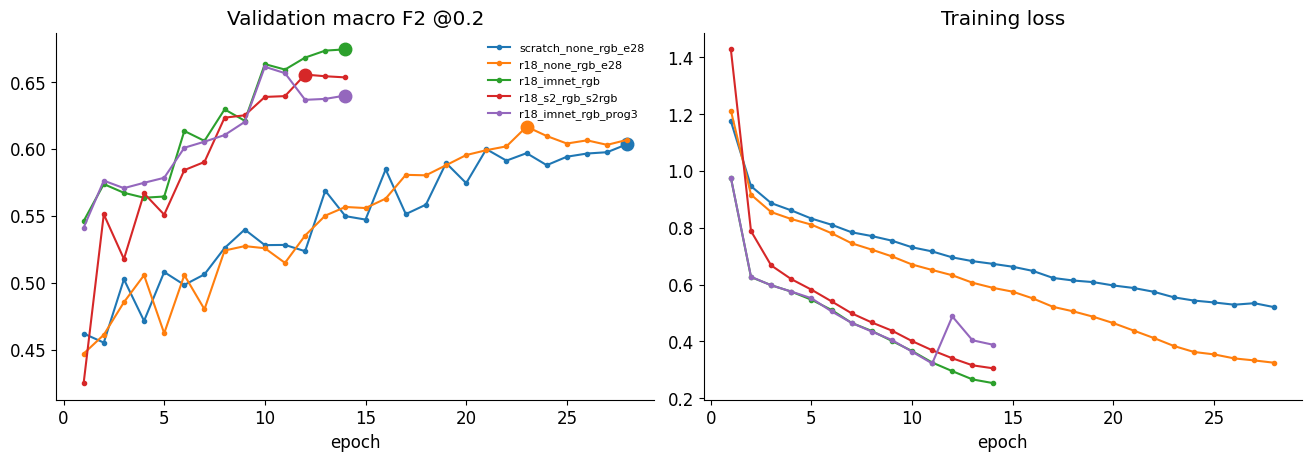

In [8]:
CURVES = ["scratch_none_rgb_e28", "r18_none_rgb_e28", "r18_imnet_rgb", "r18_s2_rgb_s2rgb", "r18_imnet_rgb_prog3"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for n in [c for c in CURVES if c in RUN and RUN[c]["hist"]]:
    h, best = RUN[n]["hist"], RUN[n]["meta"].get("best_epoch")
    ep = [e["epoch"] for e in h]
    line, = ax[0].plot(ep, [e["val_macro_f2_fixed"] for e in h], marker=".", label=n)
    ax[1].plot(ep, [e["train_loss"] for e in h], marker=".", color=line.get_color())
    if best in ep:
        ax[0].plot(best, h[ep.index(best)]["val_macro_f2_fixed"], "o", ms=9, color=line.get_color())
ax[0].set(title="Validation macro F2 @0.2", xlabel="epoch"); ax[1].set(title="Training loss", xlabel="epoch")
ax[0].legend(fontsize=8, frameon=False)
fig.savefig(f"{OUT}/fig_training_curves.png"); plt.show()

## 7. Free extras (no training needed)
### Ensemble
Averages the predicted probabilities of several runs, re-tunes thresholds on validation, and scores the result like any other run. Then it bootstraps the ensemble against `FINAL`. Members that make different mistakes help the most, e.g. ImageNet and Sentinel-2 models.

In [9]:
MEMBERS = ["r18_imnet_rgb_prog3", "r18_s2_rgb_s2rgb", "r18_imnet_rgb"]

def make_ensemble(members, name=None):
    """Adds the averaged run to RUN, so every function above works on it."""
    members = [m for m in members if m in RUN]
    name = name or "ens(" + "+".join(members) + ")"
    RUN[name] = dict(meta={"n_params": sum(RUN[m]["meta"].get("n_params") or 0 for m in members)}, hist=[],
                     vp=np.mean([RUN[m]["vp"] for m in members], 0), vy=first["vy"],
                     tp=np.mean([RUN[m]["tp"] for m in members], 0), ty=first["ty"],
                     vidx=first["vidx"], tidx=first["tidx"])
    _EVAL.pop(name, None)
    return name

ens = make_ensemble(MEMBERS)
show = [m for m in MEMBERS if m in RUN] + [ens]
display(pd.DataFrame({n: {f"{s}_{k}": evaluate(n)[s][k] for s in ("val", "test") for k in ("defor_F2", "macro_F2")}
                      for n in show}).T.round(4))
if FINAL in RUN:
    print(f"bootstrap, ensemble minus {FINAL}:")
    for split in ("val", "test"):
        print(split); display(bootstrap(FINAL, ens, split).round(4))

,val_defor_F2,val_macro_F2,test_defor_F2,test_macro_F2
r18_imnet_rgb_prog3,0.6094,0.7003,0.6085,0.6969
r18_s2_rgb_s2rgb,0.5848,0.6959,0.5450,0.6811
r18_imnet_rgb,0.6110,0.7001,0.5951,0.6939
ens(r18_imnet_rgb_prog3+r18_s2_rgb_s2rgb+r18_imnet_rgb),0.6132,0.7123,0.5894,0.6986


bootstrap, ensemble minus r18_imnet_rgb_prog3:
val


,diff,ci_low,ci_high,verdict
defor_F2,0.00379,-0.022378,0.031162,not significant
land_macro_F2,0.013835,-0.001603,0.027561,not significant
macro_F2,0.012016,0.000012,0.022615,B better


test


,diff,ci_low,ci_high,verdict
defor_F2,-0.019156,-0.076691,0.030998,not significant
land_macro_F2,0.000671,-0.019732,0.019761,not significant
macro_F2,0.001708,-0.013977,0.016004,not significant


### Cloudy rule
In the training labels, a chip tagged `cloudy` never has land labels, because nothing on the ground is visible. This switches off all land predictions on chips predicted `cloudy` and shows the effect. It's a quick check of whether the model has already learned that rule.

In [10]:
def cloudy_rule(pred):
    pred = pred.copy()
    pred[np.ix_(pred[:, labels.index("cloudy")], LI)] = False
    return pred

for n in [REFERENCE, FINAL]:
    if n not in RUN: continue
    e, r = evaluate(n), RUN[n]
    for split, y, p in [("val", r["vy"], r["vp"]), ("test", r["ty"], r["tp"])]:
        before, after = e[split], metrics(y, p, cloudy_rule(e["pred"][split]))
        print(n, split, {k: f"{before[k]:.4f} -> {after[k]:.4f}" for k in ["defor_F2", "macro_F2", "samples_F2"]})

r18_imnet_rgb val {'defor_F2': '0.6110 -> 0.6110', 'macro_F2': '0.7001 -> 0.6993', 'samples_F2': '0.9044 -> 0.9025'}
r18_imnet_rgb test {'defor_F2': '0.5951 -> 0.5951', 'macro_F2': '0.6939 -> 0.6928', 'samples_F2': '0.9034 -> 0.8999'}
r18_imnet_rgb_prog3 val {'defor_F2': '0.6094 -> 0.6094', 'macro_F2': '0.7003 -> 0.6992', 'samples_F2': '0.9012 -> 0.8986'}
r18_imnet_rgb_prog3 test {'defor_F2': '0.6085 -> 0.6085', 'macro_F2': '0.6969 -> 0.6961', 'samples_F2': '0.9008 -> 0.8983'}


## 8. Figures for the presentation
### Overview: every configuration
Deforestation F2 for every configuration, grouped by family, with validation and test side by side. Configurations with 3 seeds show the mean, with error bars of ± 1 standard deviation.

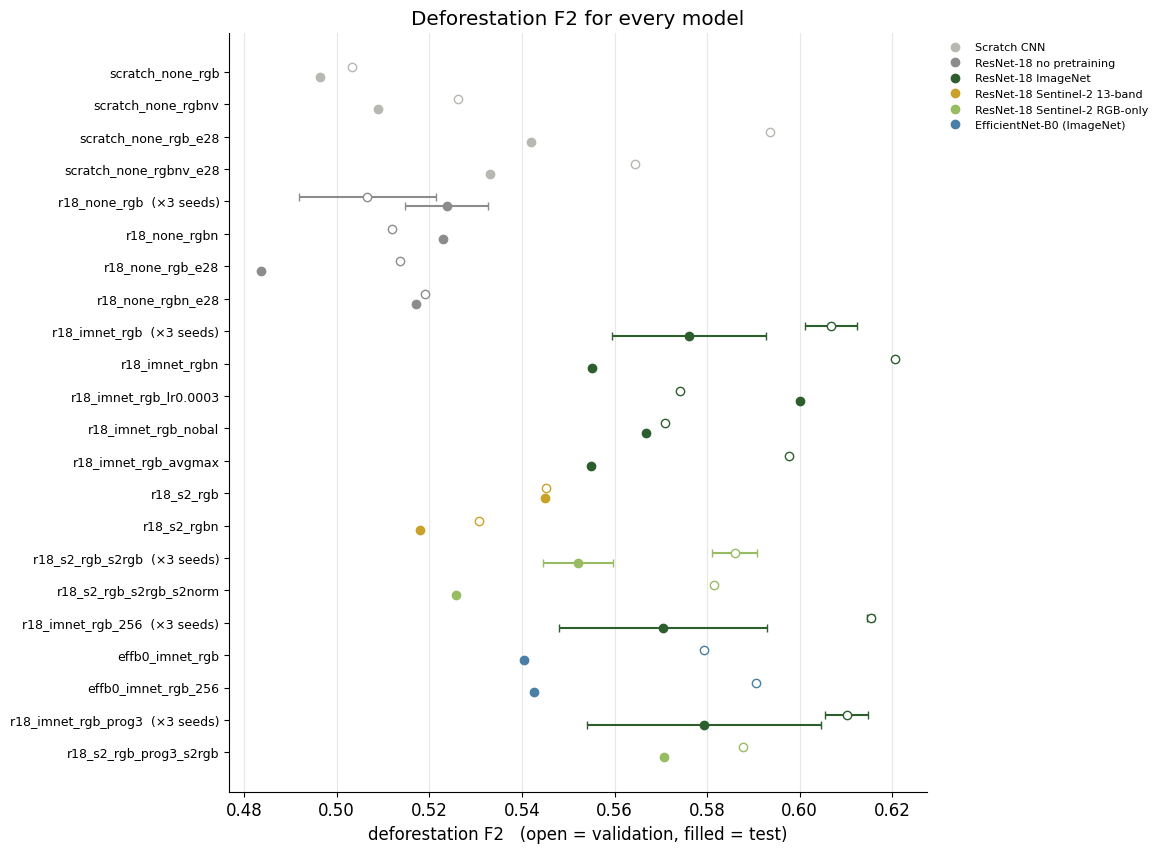

In [11]:
def config_scores(split):
    """Mean and std of deforestation F2 per configuration (std = 0 when there is only one seed)."""
    rows, done = [], set()
    for n in ORDER:
        base = re.sub(r"_s\d+$", "", n)
        if base in done or base not in RUN: continue
        done.add(base)
        runs = seed_groups().get(base, [base])
        v = np.array([evaluate(r)[split]["defor_F2"] for r in runs])
        rows.append((base, family(base), v.mean(), v.std(ddof=1) if len(v) > 1 else 0, len(v)))
    return rows

FAM_COLORS = {"Scratch CNN": "#B5B9B2", "ResNet-18 no pretraining": "#8C8C8C", "ResNet-18 ImageNet": "#2C5F2D",
              "ResNet-18 Sentinel-2 13-band": "#C9A227", "ResNet-18 Sentinel-2 RGB-only": "#97BC62",
              "EfficientNet-B0 (ImageNet)": "#4A7FA7", "other": "#666666"}
val_rows, test_rows = config_scores("val"), config_scores("test")
fig, ax = plt.subplots(figsize=(9, 0.38 * len(val_rows) + 1.5))
yy = np.arange(len(val_rows))[::-1]
for (n, fam, m, s, k), y in zip(val_rows, yy):
    ax.errorbar(m, y + 0.15, xerr=s, fmt="o", color=FAM_COLORS[fam], mfc="white", capsize=3)
for (n, fam, m, s, k), y in zip(test_rows, yy):
    ax.errorbar(m, y - 0.15, xerr=s, fmt="o", color=FAM_COLORS[fam], capsize=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{n}" + (f"  (×{k} seeds)" if k > 1 else "") for n, _, _, _, k in val_rows], fontsize=9)
ax.set_xlabel("deforestation F2   (open = validation, filled = test)")
for fam, c in FAM_COLORS.items():
    if any(r[1] == fam for r in val_rows): ax.plot([], [], "o", color=c, label=fam)
ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="x", alpha=0.3)
ax.set_title("Deforestation F2 for every model")
fig.savefig(f"{OUT}/fig_overview.png"); plt.show()

### Per-label F2 and precision-recall curves: reference vs. final model (test)

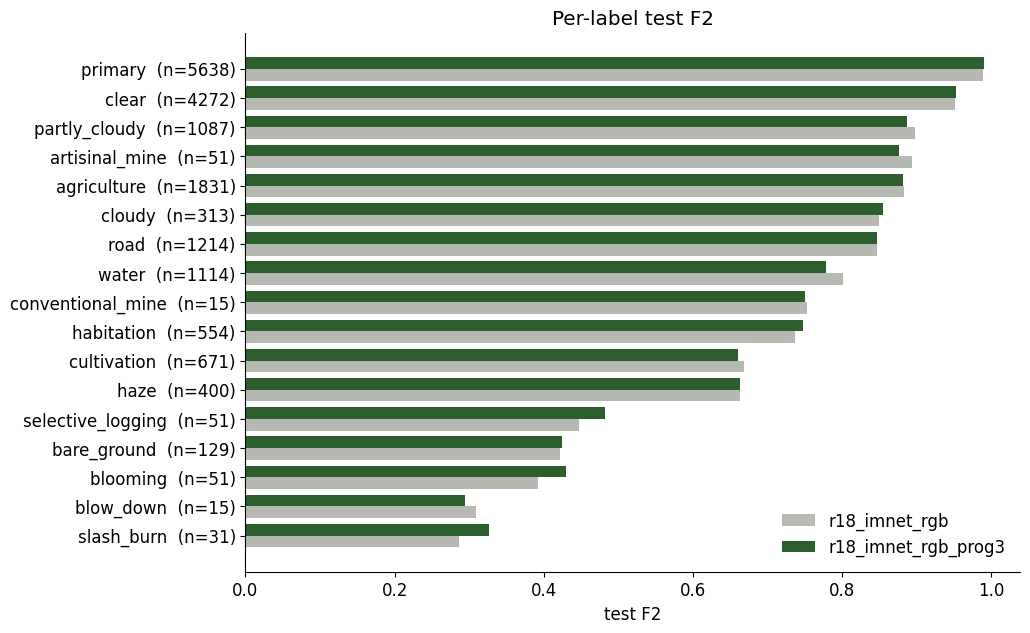

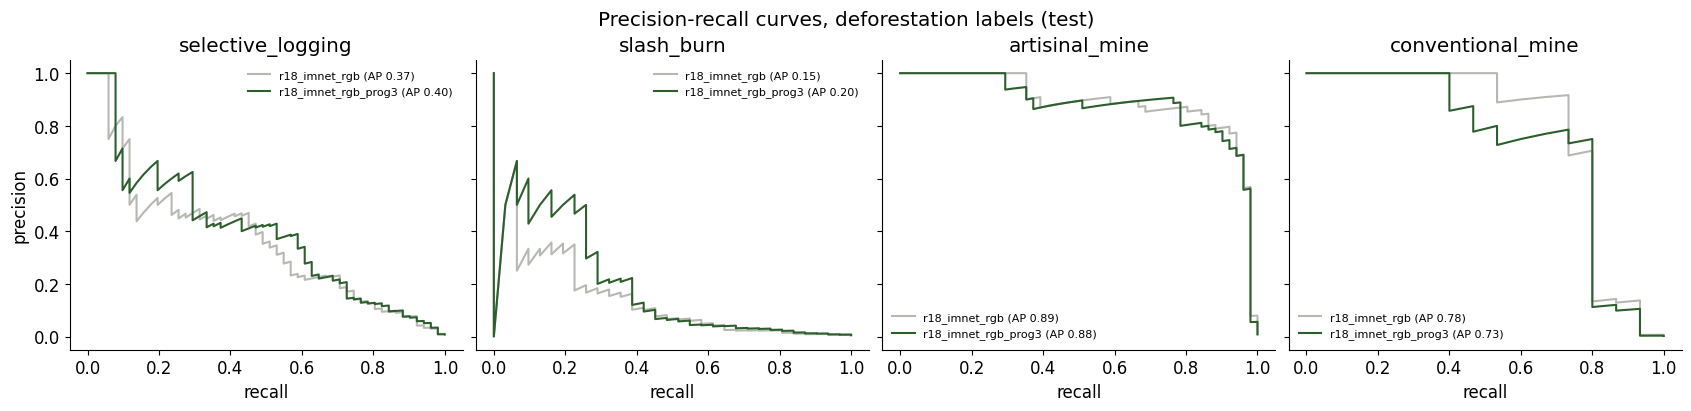

In [12]:
if REFERENCE in RUN and FINAL in RUN:
    a, b = evaluate(REFERENCE)["per_label"]["test"], evaluate(FINAL)["per_label"]["test"]
    order = a["F2"].sort_values().index
    fig, ax = plt.subplots(figsize=(10, 7)); yy = np.arange(len(order))
    ax.barh(yy - 0.2, a.loc[order, "F2"], 0.4, label=REFERENCE, color="#B5B9B2")
    ax.barh(yy + 0.2, b.loc[order, "F2"], 0.4, label=FINAL, color="#2C5F2D")
    ax.set_yticks(yy); ax.set_yticklabels([f"{l}  (n={a.loc[l, 'positives']})" for l in order])
    ax.set_xlabel("test F2"); ax.legend(frameon=False); ax.set_title("Per-label test F2")
    fig.savefig(f"{OUT}/fig_per_label_f2.png"); plt.show()
    a.join(b, lsuffix="_" + REFERENCE, rsuffix="_" + FINAL).round(3).to_csv(f"{OUT}/per_label_test.csv")

    fig, axes = plt.subplots(1, len(DEFOR), figsize=(4.2 * len(DEFOR), 4), sharey=True, constrained_layout=True)
    for ax, l in zip(axes, DEFOR):
        j = labels.index(l)
        for n, c in [(REFERENCE, "#B5B9B2"), (FINAL, "#2C5F2D")]:
            y, p = RUN[n]["ty"][:, j], RUN[n]["tp"][:, j]
            if y.sum() == 0: continue
            pr, rc, _ = precision_recall_curve(y, p)
            ax.plot(rc, pr, color=c, label=f"{n} (AP {average_precision_score(y, p):.2f})")
        ax.set_title(l); ax.set_xlabel("recall"); ax.legend(fontsize=8, frameon=False)
    axes[0].set_ylabel("precision"); fig.suptitle("Precision-recall curves, deforestation labels (test)")
    fig.savefig(f"{OUT}/fig_pr_curves_defor.png"); plt.show()

### Accuracy vs. cost
Each configuration's seed-42 run: validation deforestation F2 against model size, with marker size showing training time per epoch.

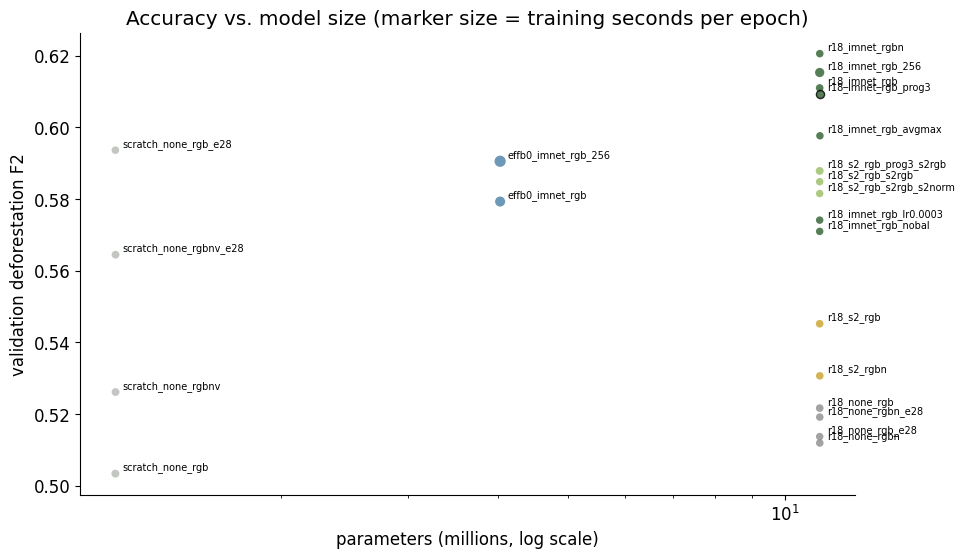

tables and figures saved in /content/drive/MyDrive/amazon_caches/ladder_runs_v2/eval


In [13]:
pts = [n for n in ORDER if not re.search(r"_s\d+$", n) and RUN[n]["meta"].get("n_params")]
fig, ax = plt.subplots(figsize=(10, 6))
for n in pts:
    s, v = RUN[n]["meta"], evaluate(n)["val"]["defor_F2"]
    ax.scatter(s["n_params"] / 1e6, v, s=20 + 2 * (s.get("train_s_per_epoch") or 0),
               color=FAM_COLORS[family(n)], alpha=0.8, edgecolor="black" if n == FINAL else "none")
    ax.annotate(n, (s["n_params"] / 1e6, v), textcoords="offset points", xytext=(5, 3), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("parameters (millions, log scale)"); ax.set_ylabel("validation deforestation F2")
ax.set_title("Accuracy vs. model size (marker size = training seconds per epoch)")
fig.savefig(f"{OUT}/fig_accuracy_vs_cost.png"); plt.show()
print("tables and figures saved in", OUT)